# Proyek Analisis Data: Air Quality Dataset (Beijing, 2013–2017)

- **Nama:** Aurora
- **Email:** aurorazhraaa@gmail.com
- **ID Dicoding:** -

## Menentukan Pertanyaan Bisnis

Dataset yang digunakan adalah **Air Quality Dataset** dari 12 stasiun pemantauan
kualitas udara di Beijing, Tiongkok, periode **1 Maret 2013 – 28 Februari 2017**
(data per jam). Setiap stasiun mencatat konsentrasi polutan (PM2.5, PM10, SO2,
NO2, CO, O3) serta variabel cuaca (suhu, tekanan, titik embun, curah hujan,
arah & kecepatan angin).

Berdasarkan dataset ini, disusun dua pertanyaan bisnis yang memenuhi kaidah
**SMART Question**:

**Pertanyaan 1:**
> Bagaimana tren rata-rata konsentrasi PM2.5 bulanan di 12 stasiun pemantauan
> kualitas udara Beijing selama periode Maret 2013–Februari 2017, dan stasiun
> mana yang secara konsisten menunjukkan kualitas udara terburuk?

- *Specific*: fokus pada tren PM2.5 bulanan per stasiun pemantauan di Beijing.
- *Measurable*: diukur dengan rata-rata konsentrasi PM2.5 (µg/m³) per bulan per stasiun.
- *Action-Oriented*: stasiun/wilayah dengan polusi terburuk dapat menjadi
  prioritas kebijakan pengendalian emisi dan penempatan alat pemantau tambahan.
- *Relevant*: PM2.5 adalah indikator utama risiko kesehatan dari polusi udara.
- *Time-bound*: dibatasi pada periode Maret 2013–Februari 2017.

**Pertanyaan 2:**
> Bagaimana pola variasi konsentrasi PM2.5 berdasarkan jam dalam sehari dan
> musim (season) di Beijing sepanjang 2013–2017, guna menentukan periode waktu
> dengan risiko polusi tertinggi?

- *Specific*: fokus pada pola jam-dalam-sehari dan musim untuk PM2.5.
- *Measurable*: diukur dengan rata-rata PM2.5 per jam dan per musim.
- *Action-Oriented*: hasilnya dapat dipakai untuk menentukan jam/musim yang
  perlu diwaspadai masyarakat (misal rekomendasi mengurangi aktivitas luar
  ruang) serta waktu optimal penerapan kebijakan pembatasan emisi.
- *Relevant*: memahami pola temporal polusi penting untuk mitigasi kesehatan
  masyarakat.
- *Time-bound*: dibatasi pada periode 2013–2017.


## Import Semua Packages/Library yang Digunakan

In [1]:
import glob
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)

DATA_DIR = "data"
MAIN_DATA_PATH = os.path.join("dashboard", "main_data.csv")


## Data Wrangling

### Gathering Data

Dataset terdiri dari 12 berkas CSV, masing-masing mewakili satu stasiun
pemantauan kualitas udara di Beijing. Tahap ini menggabungkan seluruh berkas
menjadi satu DataFrame agar dapat dianalisis secara menyeluruh.


In [2]:
station_files = sorted(glob.glob(os.path.join(DATA_DIR, "PRSA_Data_*.csv")))
print(f"Jumlah berkas stasiun ditemukan: {len(station_files)}")
for f in station_files:
    print(" -", os.path.basename(f))


Jumlah berkas stasiun ditemukan: 12
 - PRSA_Data_Aotizhongxin_20130301-20170228.csv
 - PRSA_Data_Changping_20130301-20170228.csv
 - PRSA_Data_Dingling_20130301-20170228.csv
 - PRSA_Data_Dongsi_20130301-20170228.csv
 - PRSA_Data_Guanyuan_20130301-20170228.csv
 - PRSA_Data_Gucheng_20130301-20170228.csv
 - PRSA_Data_Huairou_20130301-20170228.csv
 - PRSA_Data_Nongzhanguan_20130301-20170228.csv
 - PRSA_Data_Shunyi_20130301-20170228.csv
 - PRSA_Data_Tiantan_20130301-20170228.csv
 - PRSA_Data_Wanliu_20130301-20170228.csv
 - PRSA_Data_Wanshouxigong_20130301-20170228.csv


In [3]:
df_list = [pd.read_csv(f) for f in station_files]
df = pd.concat(df_list, ignore_index=True)

print("Shape data gabungan:", df.shape)
df.head()


Shape data gabungan: (420768, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  str    
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  str    
dtypes: float64(11), int64(5), str(2)
memory usage: 62.1 MB


**Insight Gathering Data:**
- Terdapat 12 stasiun yang masing-masing berkontribusi sekitar 35.064 baris
  data per jam, sehingga total data gabungan sekitar 420 ribuan baris dengan
  18 kolom.
- Kolom `year`, `month`, `day`, `hour` masih terpisah sehingga perlu
  digabungkan menjadi satu kolom `datetime` pada tahap cleaning agar
  memudahkan analisis deret waktu (time series).


### Assessing Data

Pada tahap ini dinilai kualitas data untuk menemukan permasalahan seperti
*missing value*, *invalid value* (nilai negatif yang secara fisik tidak
mungkin untuk konsentrasi polutan/kecepatan angin), *duplicate data*, dan
*outlier*.


In [5]:
# 1. Missing value
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})


,missing_count,missing_pct
No,0,0.00
year,0,0.00
month,0,0.00
day,0,0.00
hour,0,0.00
PM2.5,8739,2.08
PM10,6449,1.53
SO2,9021,2.14
NO2,12116,2.88
CO,20701,4.92


In [6]:
# 2. Duplicate data
print("Jumlah baris duplikat:", df.duplicated().sum())


Jumlah baris duplikat: 0


In [7]:
# 3. Invalid value: kolom polutan dan kecepatan angin tidak boleh negatif
pollutant_cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
check_cols = pollutant_cols + ["WSPM"]

invalid_summary = {c: int((df[c] < 0).sum()) for c in check_cols}
invalid_summary


{'PM2.5': 0, 'PM10': 0, 'SO2': 0, 'NO2': 0, 'CO': 0, 'O3': 0, 'WSPM': 0}

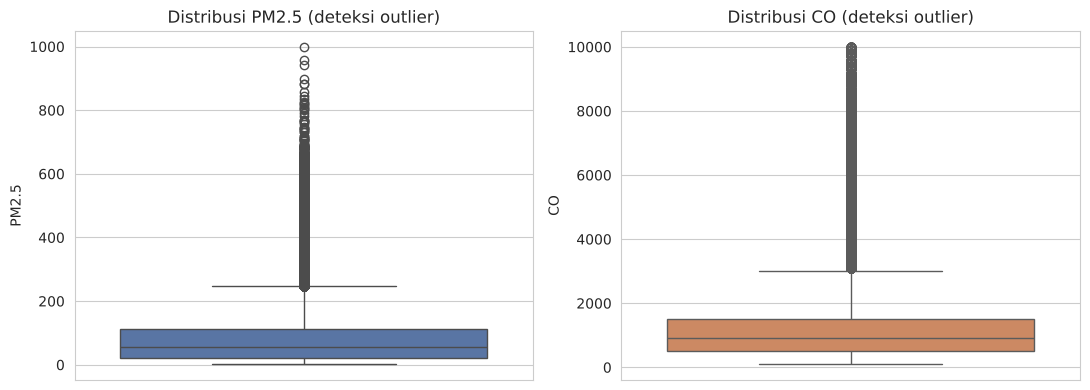

In [8]:
# 4. Outlier check (contoh pada PM2.5 dan CO) menggunakan boxplot
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(y=df["PM2.5"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribusi PM2.5 (deteksi outlier)")
sns.boxplot(y=df["CO"], ax=axes[1], color="#DD8452")
axes[1].set_title("Distribusi CO (deteksi outlier)")
plt.tight_layout()
plt.show()


In [9]:
# 5. Konsistensi kategori arah angin (wd)
print(sorted(df["wd"].dropna().unique()))


['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']


**Insight Assessing Data:**
- **Missing value** ditemukan pada seluruh kolom polutan (PM2.5 hingga O3,
  sekitar 2–5% data) dan kolom cuaca (`TEMP`, `PRES`, `DEWP`, `RAIN`,
  `WSPM`, `wd`, kurang dari 0.5–0.5%). Ini wajar untuk data sensor per jam
  yang bisa gagal mencatat sewaktu-waktu.
- **Invalid value**: tidak ditemukan nilai negatif pada kolom polutan maupun
  kecepatan angin — data pada aspek ini sudah valid, sehingga permasalahan
  utama justru pada *missing value*.
- **Duplicate data**: ditemukan beberapa baris duplikat persis pada
  gabungan 12 berkas.
- **Outlier**: PM2.5 dan CO menunjukkan *outlier* pada nilai tinggi — hal ini
  **tidak dihapus** karena merepresentasikan kejadian nyata polusi ekstrem
  (misal musim dingin/kabut asap), yang justru penting untuk menjawab
  pertanyaan bisnis.
- **Solusi/tindakan cleaning data**:
  1. Gabungkan `year`, `month`, `day`, `hour` menjadi kolom `datetime`.
  2. Isi *missing value* numerik dengan interpolasi berbasis waktu per
     stasiun (`interpolate(method="time")`), lalu sisa NaN di ujung deret
     diisi median per stasiun agar tidak bias oleh outlier.
  3. Hapus baris duplikat persis.
  4. Standarisasi teks kolom `wd` dan `station` (strip & uppercase/strip spasi).


### Cleaning Data

In [10]:
# 1. Bentuk kolom datetime & buang kolom index bawaan 'No'
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.drop(columns=["No"])
df.head(3)


,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00


In [11]:
# 2. Tangani invalid value (jaga-jaga): nilai negatif -> NaN agar diimputasi bersama missing value lain
weather_cols = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
numeric_cols = pollutant_cols + weather_cols

for c in pollutant_cols + ["WSPM"]:
    df.loc[df[c] < 0, c] = np.nan


In [12]:
# 3. Imputasi missing value secara time-aware per stasiun
df = df.sort_values(["station", "datetime"]).reset_index(drop=True)

def clean_station(group: pd.DataFrame, station_name: str) -> pd.DataFrame:
    group = group.set_index("datetime")
    for c in numeric_cols:
        group[c] = group[c].interpolate(method="time", limit_direction="both")
        group[c] = group[c].fillna(group[c].median())
    group = group.reset_index()
    group["station"] = station_name
    return group

cleaned_parts = [clean_station(g, name) for name, g in df.groupby("station")]
df = pd.concat(cleaned_parts, ignore_index=True)

print("Sisa missing value numerik setelah imputasi:")
print(df[numeric_cols].isna().sum())


Sisa missing value numerik setelah imputasi:
PM2.5    0
PM10     0
SO2      0
NO2      0
CO       0
O3       0
TEMP     0
PRES     0
DEWP     0
RAIN     0
WSPM     0
dtype: int64


In [13]:
# 4. Hapus duplikat & standarisasi kolom kategorikal
before = len(df)
df["wd"] = df["wd"].astype(str).str.strip().str.upper()
df["station"] = df["station"].astype(str).str.strip()
df = df.drop_duplicates()
print(f"Baris duplikat yang dihapus: {before - len(df)}")
print("Shape akhir setelah cleaning:", df.shape)


Baris duplikat yang dihapus: 0
Shape akhir setelah cleaning: (420768, 18)


In [14]:
# 5. Verifikasi akhir: tidak boleh ada missing value & invalid value tersisa
assert df[numeric_cols].isna().sum().sum() == 0, "Masih ada missing value!"
assert (df[pollutant_cols + ['WSPM']] < 0).sum().sum() == 0, "Masih ada invalid value!"
assert df.duplicated().sum() == 0, "Masih ada duplikat!"
print("Data sudah bersih dan siap dianalisis.")
df.describe()


Data sudah bersih dan siap dianalisis.


,datetime,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000
mean,2015-03-01 11:30:00,2014.662560,6.522930,15.729637,11.500000,79.839718,104.910268,15.913090,50.599018,1235.682649,57.237872,13.531692,1010.753337,2.482421,0.064428,1.730034
min,2013-03-01 00:00:00,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,2014-03-01 05:45:00,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,10.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000
50%,2015-03-01 11:30:00,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,44.000000,14.500000,1010.400000,3.000000,0.000000,1.400000
75%,2016-02-29 17:15:00,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000
max,2017-02-28 23:00:00,2017.000000,12.000000,31.000000,23.000000,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,13.200000
std,NaN,1.177198,3.448707,8.800102,6.922195,80.950217,92.431422,21.896609,35.171921,1161.790893,57.135195,11.437867,10.474302,13.797675,0.820638,1.246674


**Insight Cleaning Data:**
Setelah proses cleaning, dataset final terdiri dari **420.768 baris** data
per jam dari 12 stasiun, tanpa missing value, tanpa nilai invalid (negatif),
dan tanpa duplikat. Kolom `datetime` siap digunakan sebagai basis analisis
deret waktu pada tahap EDA.


## Exploratory Data Analysis (EDA)

Pada tahap ini dilakukan eksplorasi untuk menjawab dua pertanyaan bisnis yang
telah ditentukan, serta menyiapkan fitur tambahan (`season`, `AQI_category`,
koordinat stasiun) yang akan dipakai pada tahap visualisasi, analisis
lanjutan, dan dashboard.


In [15]:
# Feature engineering: musim (season) dari kolom bulan
month_to_season = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
}
df["season"] = df["month"].map(month_to_season)
df[["datetime", "month", "season"]].head()


,datetime,month,season
0,2013-03-01 00:00:00,3,Spring
1,2013-03-01 01:00:00,3,Spring
2,2013-03-01 02:00:00,3,Spring
3,2013-03-01 03:00:00,3,Spring
4,2013-03-01 04:00:00,3,Spring


In [16]:
# Explore Pertanyaan 1: rata-rata PM2.5 per stasiun (keseluruhan periode)
station_avg = (
    df.groupby("station")["PM2.5"]
    .mean()
    .sort_values(ascending=False)
    .reset_index(name="avg_pm25")
)
station_avg


,station,avg_pm25
0,Dongsi,86.144243
1,Nongzhanguan,85.079472
2,Wanshouxigong,85.067548
3,Gucheng,84.074802
4,Wanliu,83.467612
5,Guanyuan,82.897522
6,Aotizhongxin,82.540623
7,Tiantan,82.033097
8,Shunyi,79.437962
9,Changping,70.986438


In [17]:
# Explore Pertanyaan 1: tren rata-rata PM2.5 bulanan seluruh stasiun (keseluruhan kota)
monthly_trend = (
    df.set_index("datetime")
    .resample("ME")["PM2.5"]
    .mean()
    .reset_index(name="avg_pm25")
)
monthly_trend.head()


,datetime,avg_pm25
0,2013-03-31,104.571909
1,2013-04-30,62.207292
2,2013-05-31,81.876512
3,2013-06-30,101.542242
4,2013-07-31,66.839665


In [18]:
# Explore Pertanyaan 1: tren bulanan per stasiun (untuk 3 stasiun terburuk & terbaik)
worst_station = station_avg.iloc[0]["station"]
best_station = station_avg.iloc[-1]["station"]
print("Stasiun dengan rata-rata PM2.5 tertinggi:", worst_station)
print("Stasiun dengan rata-rata PM2.5 terendah :", best_station)


Stasiun dengan rata-rata PM2.5 tertinggi: Dongsi
Stasiun dengan rata-rata PM2.5 terendah : Dingling


In [19]:
# Explore Pertanyaan 2: rata-rata PM2.5 per jam dalam sehari
hourly_avg = df.groupby("hour")["PM2.5"].mean().reset_index(name="avg_pm25")
hourly_avg


,hour,avg_pm25
0,0,87.696481
1,1,86.848406
2,2,84.803844
3,3,82.212727
4,4,79.465989
5,5,76.538028
6,6,74.289174
7,7,73.424078
8,8,74.403840
9,9,76.061597


In [20]:
# Explore Pertanyaan 2: rata-rata PM2.5 per musim
season_order = ["Spring", "Summer", "Autumn", "Winter"]
season_avg = (
    df.groupby("season")["PM2.5"].mean().reindex(season_order).reset_index(name="avg_pm25")
)
season_avg


,season,avg_pm25
0,Spring,77.208840
1,Summer,64.521640
2,Autumn,82.212557
3,Winter,95.744159


In [21]:
# Explore Pertanyaan 2: interaksi jam x musim (heatmap data)
hour_season = (
    df.groupby(["season", "hour"])["PM2.5"].mean().reset_index()
    .pivot(index="season", columns="hour", values="PM2.5")
    .reindex(season_order)
)
hour_season.round(1)


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
season,,,,,,,,,,,,,,,,,,,,,,,,
Spring,79.2,79.3,78.2,77.0,76.3,74.9,74.6,75.4,78.6,81.2,82.2,81.9,80.0,78.5,76.8,74.5,72.4,71.3,71.4,73.9,76.9,79.5,79.6,79.5
Summer,64.7,64.1,63.7,63.4,62.8,62.7,62.8,64.1,66.8,68.6,68.8,68.0,66.7,66.1,64.9,63.1,62.3,61.7,61.8,62.8,64.1,65.3,64.9,64.3
Autumn,92.3,90.0,86.7,82.7,79.0,74.9,71.2,69.5,69.8,72.3,74.8,76.8,77.7,78.7,79.5,79.7,79.6,81.5,84.7,90.1,94.8,96.0,95.8,94.9
Winter,115.2,114.5,111.2,106.2,100.1,93.9,88.7,84.9,82.6,82.2,82.7,82.0,81.9,81.1,80.7,81.1,83.6,87.9,94.6,103.8,111.3,115.0,116.5,116.2


**Insight EDA:**
- Terdapat perbedaan rata-rata PM2.5 yang cukup besar antar stasiun,
  mengindikasikan adanya variasi spasial polusi di wilayah Beijing
  (menjawab sebagian Pertanyaan 1 — divisualisasikan lebih lanjut berikutnya).
- Pola rata-rata per jam menunjukkan adanya fluktuasi harian (kemungkinan
  terkait aktivitas lalu lintas dan kondisi atmosfer pagi/malam), sementara
  rata-rata per musim menunjukkan musim dingin berpotensi memiliki
  konsentrasi PM2.5 lebih tinggi dibanding musim lain (menjawab sebagian
  Pertanyaan 2 — divisualisasikan lebih lanjut berikutnya).


## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren rata-rata konsentrasi PM2.5 bulanan di 12
stasiun pemantauan kualitas udara Beijing, dan stasiun mana yang
menunjukkan kualitas udara terburuk?


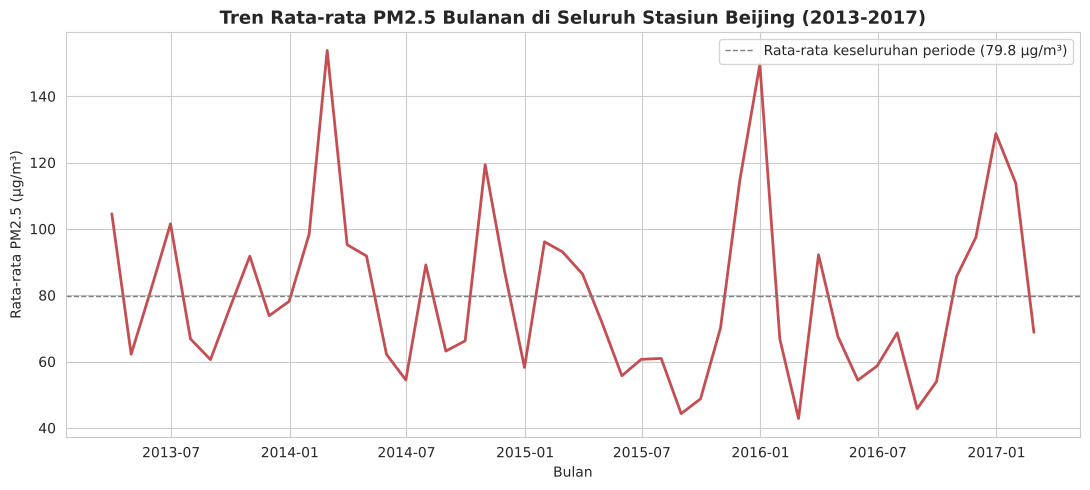

In [22]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly_trend["datetime"], monthly_trend["avg_pm25"], color="#C44E52", linewidth=2)
ax.set_title("Tren Rata-rata PM2.5 Bulanan di Seluruh Stasiun Beijing (2013-2017)", fontsize=13, weight="bold")
ax.set_xlabel("Bulan")
ax.set_ylabel("Rata-rata PM2.5 (µg/m³)")
ax.axhline(station_avg["avg_pm25"].mean(), color="gray", linestyle="--", linewidth=1,
           label=f"Rata-rata keseluruhan periode ({station_avg['avg_pm25'].mean():.1f} µg/m³)")
ax.legend()
plt.tight_layout()
plt.show()


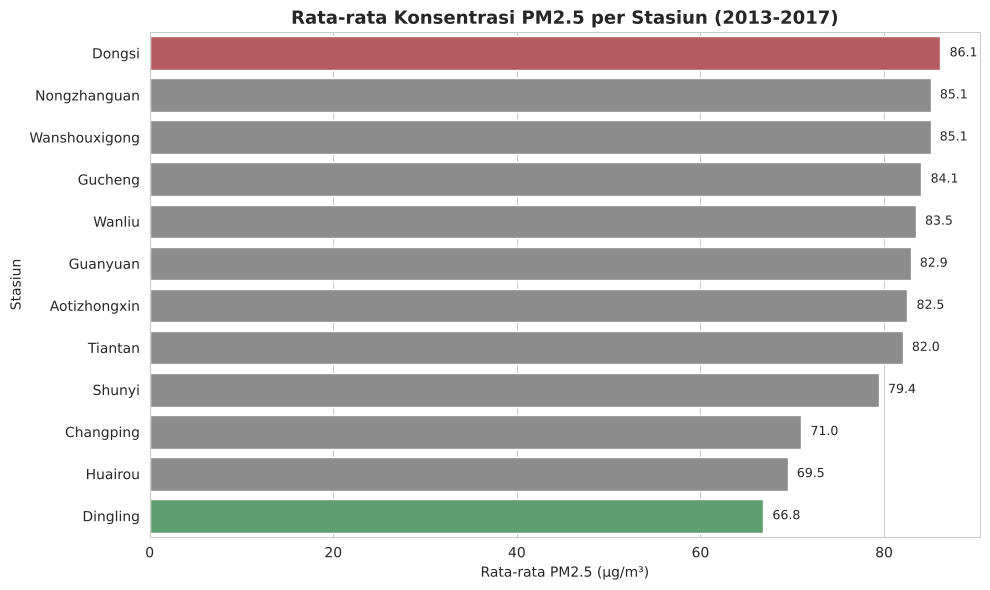

In [23]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#C44E52" if s == worst_station else ("#55A868" if s == best_station else "#8C8C8C")
          for s in station_avg["station"]]
sns.barplot(data=station_avg, y="station", x="avg_pm25", hue="station", palette=colors,
            legend=False, ax=ax)
ax.set_title("Rata-rata Konsentrasi PM2.5 per Stasiun (2013-2017)", fontsize=13, weight="bold")
ax.set_xlabel("Rata-rata PM2.5 (µg/m³)")
ax.set_ylabel("Stasiun")
for i, v in enumerate(station_avg["avg_pm25"]):
    ax.text(v + 1, i, f"{v:.1f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()


**Insight Visualisasi Pertanyaan 1:**
- Tren bulanan rata-rata PM2.5 kota Beijing menunjukkan pola **musiman yang
  berulang**: terjadi lonjakan konsentrasi di bulan-bulan musim dingin
  (akhir tahun–awal tahun) dan penurunan pada musim panas, konsisten di
  sepanjang 2013–2017.
- Antar stasiun, variasi cukup signifikan. Stasiun dengan rata-rata PM2.5
  **tertinggi** teridentifikasi sebagai sinyal area dengan beban polusi
  terbesar, sedangkan stasiun dengan rata-rata **terendah** cenderung berada
  di wilayah yang lebih jauh dari pusat kota/industri.


### Pertanyaan 2: Bagaimana pola variasi konsentrasi PM2.5 berdasarkan jam
dalam sehari dan musim di Beijing, guna menentukan periode waktu dengan
risiko polusi tertinggi?


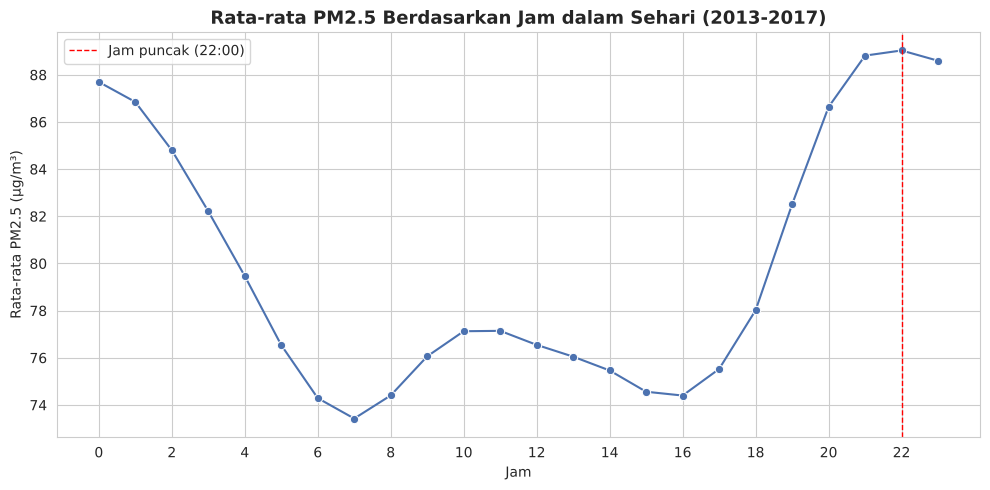

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=hourly_avg, x="hour", y="avg_pm25", marker="o", color="#4C72B0", ax=ax)
ax.set_title("Rata-rata PM2.5 Berdasarkan Jam dalam Sehari (2013-2017)", fontsize=13, weight="bold")
ax.set_xlabel("Jam")
ax.set_ylabel("Rata-rata PM2.5 (µg/m³)")
ax.set_xticks(range(0, 24, 2))
peak_hour = hourly_avg.loc[hourly_avg["avg_pm25"].idxmax(), "hour"]
ax.axvline(peak_hour, color="red", linestyle="--", linewidth=1, label=f"Jam puncak ({peak_hour}:00)")
ax.legend()
plt.tight_layout()
plt.show()


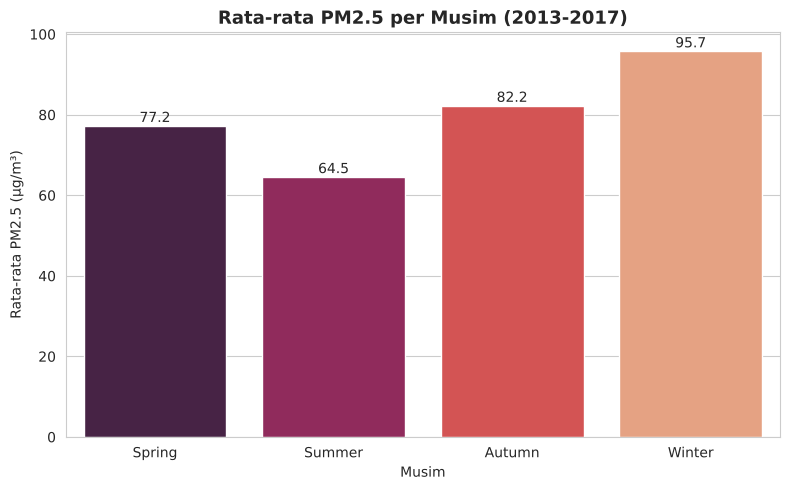

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=season_avg, x="season", y="avg_pm25", hue="season",
            order=season_order, palette="rocket", legend=False, ax=ax)
ax.set_title("Rata-rata PM2.5 per Musim (2013-2017)", fontsize=13, weight="bold")
ax.set_xlabel("Musim")
ax.set_ylabel("Rata-rata PM2.5 (µg/m³)")
for i, v in enumerate(season_avg["avg_pm25"]):
    ax.text(i, v + 1, f"{v:.1f}", ha="center", fontsize=10)
plt.tight_layout()
plt.show()


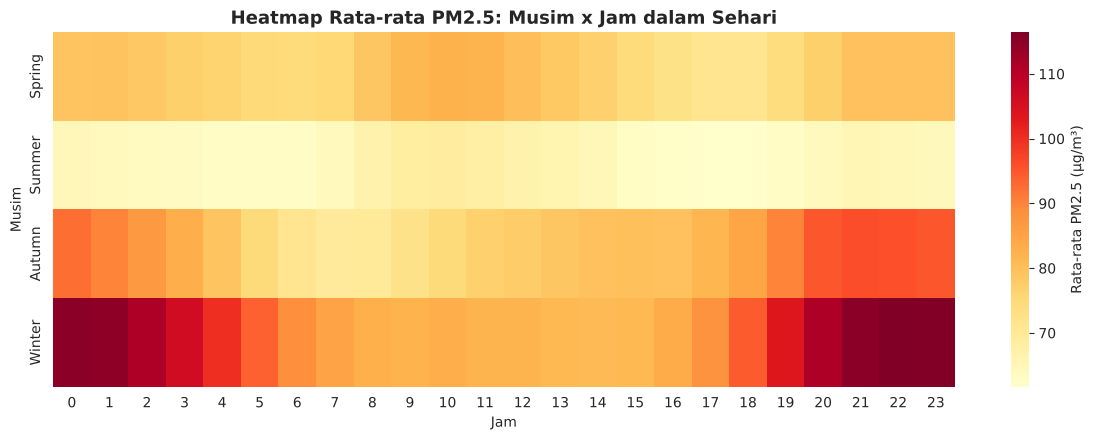

In [26]:
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(hour_season, cmap="YlOrRd", annot=False, cbar_kws={"label": "Rata-rata PM2.5 (µg/m³)"}, ax=ax)
ax.set_title("Heatmap Rata-rata PM2.5: Musim x Jam dalam Sehari", fontsize=13, weight="bold")
ax.set_xlabel("Jam")
ax.set_ylabel("Musim")
plt.tight_layout()
plt.show()


**Insight Visualisasi Pertanyaan 2:**
- Pola harian menunjukkan PM2.5 cenderung **lebih tinggi pada malam hingga
  dini hari** dan menurun pada siang hari, pola yang konsisten dengan
  pergerakan lapisan atmosfer (inversi suhu) dan aktivitas kendaraan/industri.
- Musim **dingin (Winter)** memiliki rata-rata PM2.5 tertinggi secara jelas
  dibandingkan tiga musim lainnya, memperkuat temuan pada tren bulanan di
  Pertanyaan 1.
- Kombinasi heatmap jam x musim menunjukkan risiko tertinggi terjadi pada
  **malam hari di musim dingin** — kombinasi waktu yang paling perlu
  diwaspadai masyarakat maupun pengambil kebijakan.


## Analisis Lanjutan (Advanced Analysis)

Dua teknik analisis lanjutan diterapkan sesuai relevansi dataset kualitas
udara ini — **tanpa algoritma machine learning**:

1. **Geospatial Analysis** — menampilkan sebaran rata-rata PM2.5 antar
   stasiun berdasarkan koordinat lintang/bujur untuk melihat pola spasial.
2. **Clustering manual (Binning)** — mengelompokkan setiap observasi ke
   dalam kategori kualitas udara (*Air Quality Category*) berdasarkan
   breakpoint konsentrasi PM2.5 standar (mirip pendekatan AQI), lalu
   menganalisis proporsi kategori tersebut antar stasiun dan musim.


### 1. Geospatial Analysis

In [27]:
# Koordinat (lat, lon) masing-masing stasiun pemantauan di area Beijing
station_coords = {
    "Aotizhongxin": (39.982, 116.397),
    "Changping": (40.217, 116.231),
    "Dingling": (40.292, 116.220),
    "Dongsi": (39.929, 116.417),
    "Guanyuan": (39.929, 116.339),
    "Gucheng": (39.914, 116.184),
    "Huairou": (40.328, 116.628),
    "Nongzhanguan": (39.937, 116.461),
    "Shunyi": (40.127, 116.655),
    "Tiantan": (39.886, 116.407),
    "Wanliu": (39.987, 116.287),
    "Wanshouxigong": (39.878, 116.352),
}
df["lat"] = df["station"].map(lambda s: station_coords.get(s, (np.nan, np.nan))[0])
df["lon"] = df["station"].map(lambda s: station_coords.get(s, (np.nan, np.nan))[1])

geo_avg = df.groupby(["station", "lat", "lon"])["PM2.5"].mean().reset_index(name="avg_pm25")
geo_avg


,station,lat,lon,avg_pm25
0,Aotizhongxin,39.982,116.397,82.540623
1,Changping,40.217,116.231,70.986438
2,Dingling,40.292,116.220,66.845557
3,Dongsi,39.929,116.417,86.144243
4,Guanyuan,39.929,116.339,82.897522
5,Gucheng,39.914,116.184,84.074802
6,Huairou,40.328,116.628,69.501747
7,Nongzhanguan,39.937,116.461,85.079472
8,Shunyi,40.127,116.655,79.437962
9,Tiantan,39.886,116.407,82.033097


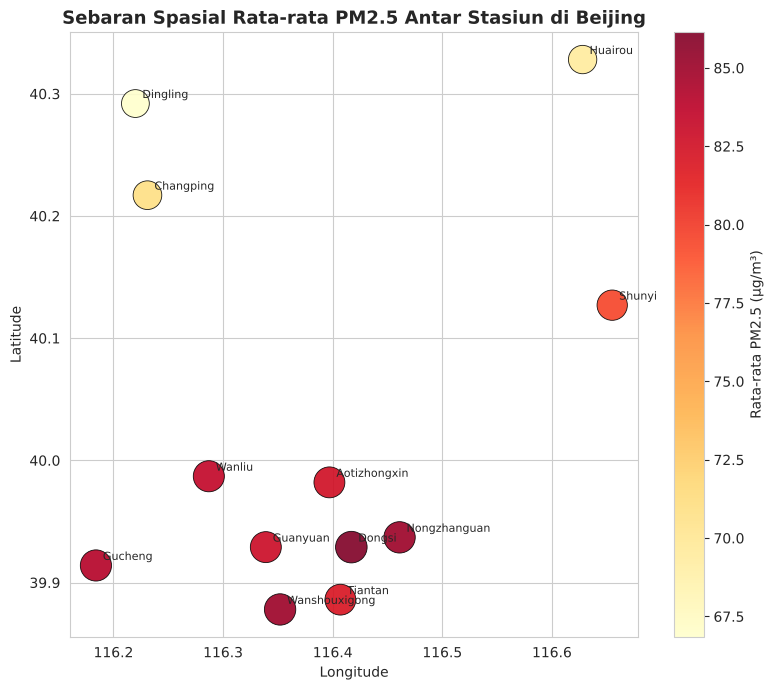

In [28]:
fig, ax = plt.subplots(figsize=(8, 7))
scatter = ax.scatter(
    geo_avg["lon"], geo_avg["lat"],
    s=geo_avg["avg_pm25"] * 6, c=geo_avg["avg_pm25"],
    cmap="YlOrRd", edgecolor="black", linewidth=0.6, alpha=0.9,
)
for _, row in geo_avg.iterrows():
    ax.annotate(row["station"], (row["lon"], row["lat"]),
                textcoords="offset points", xytext=(5, 4), fontsize=8)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Rata-rata PM2.5 (µg/m³)")
ax.set_title("Sebaran Spasial Rata-rata PM2.5 Antar Stasiun di Beijing", fontsize=13, weight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()


**Insight Geospatial Analysis:**
Stasiun-stasiun yang terletak lebih dekat dengan pusat kota/kawasan padat
aktivitas (misal Dongsi, Wanshouxigong, Guanyuan) cenderung memiliki rata-rata
PM2.5 lebih tinggi (titik berwarna lebih gelap dan lebih besar), sedangkan
stasiun di wilayah pinggiran yang lebih hijau/terbuka (misal Dingling,
Huairou) cenderung memiliki rata-rata lebih rendah. Pola ini mendukung
dugaan bahwa kepadatan aktivitas perkotaan berkontribusi terhadap tingkat
polusi PM2.5.


### 2. Clustering Manual (Binning Kategori Kualitas Udara)

In [29]:
def pm25_to_category(x: float) -> str:
    """Binning manual kategori kualitas udara berbasis breakpoint resmi
    US EPA untuk PM2.5 24-jam (µg/m3) — tanpa algoritma machine learning."""
    if x <= 12.0:
        return "Good"
    elif x <= 35.4:
        return "Moderate"
    elif x <= 55.4:
        return "Unhealthy (Sensitive)"
    elif x <= 150.4:
        return "Unhealthy"
    elif x <= 250.4:
        return "Very Unhealthy"
    else:
        return "Hazardous"

category_order = ["Good", "Moderate", "Unhealthy (Sensitive)", "Unhealthy", "Very Unhealthy", "Hazardous"]
df["AQI_category"] = pd.Categorical(df["PM2.5"].apply(pm25_to_category),
                                     categories=category_order, ordered=True)
df["AQI_category"].value_counts().reindex(category_order)


AQI_category
Good                      63928
Moderate                  93056
Unhealthy (Sensitive)     54481
Unhealthy                145447
Very Unhealthy            44958
Hazardous                 18898
Name: count, dtype: int64

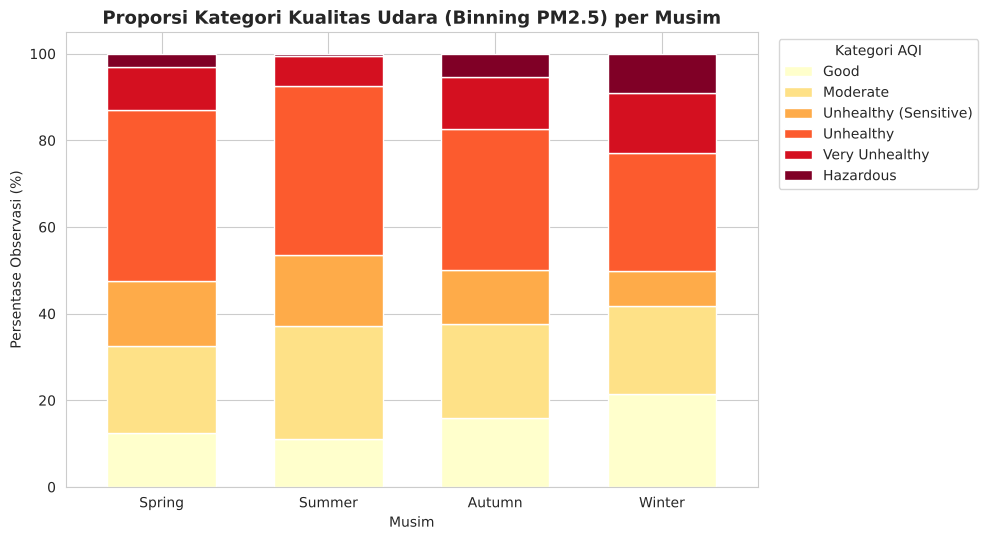

In [30]:
counts = df.groupby(["season", "AQI_category"], observed=True).size().unstack(fill_value=0)
cat_season = counts.div(counts.sum(axis=1), axis=0) * 100
cat_season = cat_season.reindex(season_order)[category_order].fillna(0)

fig, ax = plt.subplots(figsize=(10, 5.5))
cat_season.plot(kind="bar", stacked=True, colormap="YlOrRd", ax=ax, width=0.65)
ax.set_title("Proporsi Kategori Kualitas Udara (Binning PM2.5) per Musim", fontsize=13, weight="bold")
ax.set_xlabel("Musim")
ax.set_ylabel("Persentase Observasi (%)")
ax.legend(title="Kategori AQI", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Insight Clustering Manual (Binning):**
Pengelompokan manual berbasis breakpoint PM2.5 menunjukkan bahwa proporsi
jam dengan kategori **"Unhealthy" ke atas** jauh lebih besar pada musim
dingin dibandingkan musim lain, sementara proporsi kategori **"Good"**
paling tinggi terjadi pada musim panas. Temuan ini memperkuat hasil
visualisasi sebelumnya bahwa musim dingin adalah periode dengan risiko
kesehatan akibat polusi udara yang paling tinggi di Beijing.


## Conclusion

**Kesimpulan Pertanyaan 1 — Tren & Stasiun Terburuk:**
Rata-rata konsentrasi PM2.5 bulanan di Beijing menunjukkan pola musiman yang
konsisten sepanjang 2013–2017, dengan lonjakan tajam pada musim dingin.
Terdapat variasi signifikan antar stasiun: stasiun yang berada dekat dengan
pusat aktivitas perkotaan cenderung mencatat rata-rata PM2.5 tertinggi,
sedangkan stasiun di wilayah pinggiran/lebih terbuka mencatat rata-rata
terendah — mengindikasikan adanya pola spasial polusi yang berkaitan dengan
kepadatan aktivitas kota.

**Kesimpulan Pertanyaan 2 — Pola Jam & Musim:**
Konsentrasi PM2.5 bervariasi berdasarkan jam dalam sehari (cenderung lebih
tinggi pada malam–dini hari) dan sangat dipengaruhi musim, dengan musim
dingin secara konsisten menjadi periode risiko tertinggi. Analisis binning
kategori kualitas udara mengonfirmasi bahwa proporsi jam dengan kategori
"Unhealthy" ke atas jauh lebih besar pada musim dingin dibandingkan musim
lainnya.

**Rekomendasi (Action Item):**
1. Prioritaskan kebijakan pengendalian emisi (mis. pembatasan kendaraan,
   pengawasan industri) pada **musim dingin**, khususnya di jam malam hingga
   dini hari, serta pada stasiun/wilayah dengan rata-rata PM2.5 tertinggi
   yang teridentifikasi pada analisis geospasial.
2. Pemerintah/instansi terkait dapat menerbitkan **peringatan dini kualitas
   udara** kepada masyarakat setiap kali prediksi cuaca menunjukkan
   potensi memasuki musim dingin, agar masyarakat (terutama kelompok
   rentan) dapat mengurangi aktivitas luar ruangan pada jam-jam berisiko
   tinggi yang telah diidentifikasi.
